In [3]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [92]:
BRIDGE = "data/bridge_matrices.xlsx"
IMPACTS = "data/bubble_data_by_indicator_2015.xlsx"
FOOTPRINT = "M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp"
ID_COLS = ["Food","category", "sub_category", "sector"]
AGGREGATION = ["M_analyse","M_regimes_alimentaires","M_base_vg_animal"] #"M_base_agri_land","M_base_eau bleue"]
LIMITS = ["N surplus","Blue water consumption","GHG emissions","Agricultural land","Biodiversity loss - HANPP"]
SUFFIX = ["_N","_blue_water","_CO2eq","_agri_land","_HANPP"]


Import des agrégats des secteurs

In [87]:
def load_aggregated_sectors(sheet, path=BRIDGE):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    attributes = [str(v).strip() for v in raw.iloc[0, 4:]]     # Food, Cereals, ... (ligne 0)
    df = raw.iloc[2:].reset_index(drop=True)              # ligne 1 = en-têtes category/sub_category/sector
    df.columns = ID_COLS + attributes
    for c in ID_COLS:
        df[c] = df[c].astype(str).str.strip()
    df[attributes] = df[attributes].apply(pd.to_numeric).fillna(0).astype(int)  # 0/1 : appartenance à l'attribut
    df = df.set_index(ID_COLS[-1])
    return df

Import des impacts par secteur

In [82]:
def load_impacts(sheet, path=IMPACTS, row=FOOTPRINT):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    start = raw.index[raw[0].astype(str).str.startswith("Source data")][0] + 1
    block = raw.iloc[start:].set_index(0)
    block.columns = [str(c).strip() for c in block.iloc[0]]
    block = block.iloc[1:]
    
    block = block.apply(pd.to_numeric, errors="coerce")
    block = block.dropna(how="all")
    
    block.index.name = sheet
    return block

In [83]:
db_impacts=pd.read_pickle("pkl/aggregate.pkl")[[]] #récupère les secteurs (catégories, sous-catégories et food)
db_impacts=db_impacts.join(load_impacts(LIMITS[0]).loc[["Y_imp","Y_dom"]].T)
for i in range(len(LIMITS)):
    limit, suffix = LIMITS[i], SUFFIX[i]
    impact = load_impacts(limit)
    db_impacts=db_impacts.join(impact.loc[["M_imp","M_dom","M_row"]].T.add_suffix(suffix))
db_impacts.to_pickle("pkl/impacts.pkl")

In [84]:
pd.read_pickle("pkl/impacts.pkl")

,Y_imp,Y_dom,M_imp_N,M_dom_N,M_row_N,M_imp_blue_water,M_dom_blue_water,M_row_blue_water,M_imp_CO2eq,M_dom_CO2eq,M_row_CO2eq,M_imp_agri_land,M_dom_agri_land,M_row_agri_land,M_imp_HANPP,M_dom_HANPP,M_row_HANPP
sector,,,,,,,,,,,,,,,,,
Paddy rice,12.589531,111.123786,1.989383e-07,7.090982e-06,2.363631e-05,0.002317,0.002525,1.259633,0.000107,0.000376,2.456144e-03,0.081062,1.323731,6.397288,3.898873e-08,3.625879e-07,3.116650e-06
Wheat,393.416838,6143.007796,9.804582e-08,8.873836e-06,2.296390e-05,0.001130,0.000890,0.012631,0.000063,0.000291,2.417867e-03,0.046764,1.918326,4.785103,1.696099e-08,4.470634e-07,2.178718e-06
Cereal grains nec,6.170734,370.683466,6.442566e-08,7.347113e-06,1.735082e-05,0.000736,0.034199,0.073126,0.000038,0.000210,1.017015e-03,0.030665,1.130837,4.140762,1.132720e-08,4.007369e-07,2.189237e-06
"Vegetables, fruit, nuts",6666.413096,10280.107605,3.666241e-07,2.252354e-06,1.050347e-05,0.005960,0.011406,0.224259,0.000132,0.000167,5.899108e-07,0.147654,0.899907,3.178699,4.772722e-08,2.315433e-07,9.025651e-07
Oil seeds,709.186797,726.078487,1.513198e-07,4.118261e-05,1.680156e-05,0.001774,0.006259,0.100974,0.000099,0.000761,8.279985e-04,0.076610,3.668280,7.698077,2.583717e-08,8.226656e-07,1.840119e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Membership organisation services n.e.c. (91),95.863337,22590.510068,2.204345e-07,5.997452e-08,1.790537e-06,0.002062,0.000694,0.013603,0.000076,0.000069,0.000000e+00,0.086706,0.009533,0.586972,2.872476e-08,5.034518e-09,1.634473e-07
"Recreational, cultural and sporting services (92)",2481.468221,71885.084968,2.302573e-07,2.088215e-07,4.540206e-07,0.002188,0.001998,0.003042,0.000103,0.000104,1.243609e-03,0.077242,0.032714,0.165793,2.920231e-08,1.725449e-08,4.622357e-08
Other services (93),262.192337,11238.476071,3.409486e-07,1.059440e-08,6.139356e-07,0.003099,0.000611,0.008325,0.000074,0.000019,7.534788e-03,0.138203,0.001658,0.275204,4.495945e-08,9.099804e-10,7.766778e-08


In [93]:
for aggregate in AGGREGATION:
    impacts = pd.read_pickle("pkl/impacts.pkl")
    d = load_aggregated_sectors(aggregate).merge(impacts,left_on="sector", right_index=True, how="left")
    d.to_pickle("pkl/"+aggregate+".pkl")

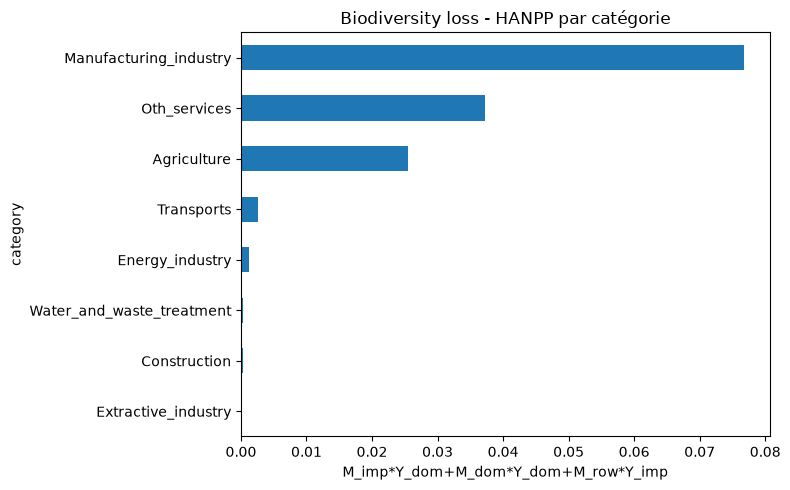

In [22]:
d.groupby("category")["impact"].sum().sort_values().plot.barh(figsize=(8, 5))
plt.xlabel(FOOTPRINT); plt.title("Biodiversity loss - HANPP par catégorie"); plt.tight_layout(); plt.show()